# 15 — Market power on a sample of days (Part 3, reduced Stages 4–5)

**Does:** runs strategic bidding for the **5 largest firms** on **11 days** chosen across the whole range of market conditions: each firm alone (Stage 4 idea), then all five together until no firm wants to change its bid (Stage 5 idea, equilibrium).

**Why a sample:** one strategy search takes ~1.3 s (notebook 14). The full runs (all 396 days, 24 firms) are **deferred**: built in `src/run_part3.py` and notebooks `15_market_power_all_days` – `17_what_ifs`, to be run and reviewed later (`docs/part3_plan.md`). This sample runs in a few minutes.

**Output:** `data/processed/strategic_sample_results.csv`. **Logged in:** `docs/model_log.md`, Step 25.

## Design (approved)

| Choice | Value |
|---|---|
| Days | Two per tightness band (spare < 10%, 10–15%, 15–20%, 20–30%, ≥ 30%): one **near a coal-tier step**, one **not**; each the day closest to its band's middle. Plus **30 May 2024**, the national peak |
| Firms | The 5 largest: UP, Maharashtra, Chhattisgarh, MP, Gujarat (the five most often pivotal, Stage 1; 45% of strategic capacity). Everyone else bids cost |
| Experiment A | Each firm **alone**, everyone else at cost |
| Experiment B | All 5 **together**: best-response iteration (each firm in turn picks its best bid given the others' current bids; a firm only moves if it gains > Rs 1,000/h), until nobody moves (*converged*), a set of bids repeats (*cycle*), or 5 rounds (*round limit*) |
| Strategy | **Bid only** (cost + adder, no withholding): Stage 3 found raising the bid always beat withholding and the joint search never gained anything, and it's 4× faster |

**Hypotheses, written before running:**
1. Every big firm marks up on most days, not only the tight ones (Stage 3: even the slack day)
2. With rivals also bidding strategically, prices end up **higher** than with any one firm alone
3. Some days **cycle** instead of settling (Bertrand–Edgeworth undercutting)

In [1]:
import sys
sys.path.insert(0, "../src")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dispatch import (LossDispatchModel, load_generators, load_demand, load_coordinates, loss_matrix,
                      daily_availability_lookup)
from bidding import (firm_blocks, best_response, equilibrium, market_summary, firm_profit,
                     make_bids, BID_ONLY)

gen = load_generators()
blocks = firm_blocks(gen)
demand = load_demand()
states = list(demand.columns)
model = LossDispatchModel(gen, loss_matrix(load_coordinates(), states), states)

national = pd.read_csv("../data/processed/market_structure_national_daily.csv", parse_dates=["Date"]).set_index("Date")
FIRMS = ["NR UP", "WR Maharashtra", "Chhattisgarh", "MP", "Gujarat"]
strategic_mw = blocks[blocks["Role"] == "strategic"].groupby("Firm")["Capacity_MW"].sum()
print(f"5 firms hold {100 * strategic_mw[FIRMS].sum() / strategic_mw.sum():.0f}% of strategic capacity")

5 firms hold 45% of strategic capacity


## The sample days

In [2]:
BANDS = {"< 10%": (0.00, 0.10, 0.075), "10–15%": (0.10, 0.15, 0.125), "15–20%": (0.15, 0.20, 0.175),
         "20–30%": (0.20, 0.30, 0.25), "≥ 30%": (0.30, 1.00, 0.40)}
picked = []
for band, (lo, hi, mid) in BANDS.items():
    for near in [True, False]:
        pool = national[(national["Tightness"] >= lo) & (national["Tightness"] < hi) & (national["Near_step"] == near)]
        d = (pool["Tightness"] - mid).abs().sort_values(kind="stable").index[0]
        picked.append({"Date": d, "Band": band, "Near_step": near})
picked.append({"Date": pd.Timestamp("2024-05-30"), "Band": "Peak day", "Near_step": bool(national.loc["2024-05-30", "Near_step"])})

sample = pd.DataFrame(picked).set_index("Date")
sample["Spare %"] = (100 * national.loc[sample.index, "Tightness"]).round(1)
sample["Pivotal firms"] = national.loc[sample.index, "Pivotal_firms"]
sample["Lowest RSI"] = national.loc[sample.index, "Lowest_RSI"].round(3)
lookup = daily_availability_lookup(pd.read_csv("../data/processed/availability_daily.csv", parse_dates=["Date"])
                                   .query("Date in @sample.index"))
sample

,Band,Near_step,Spare %,Pivotal firms,Lowest RSI
Date,,,,,
2025-01-28,< 10%,True,5.0,9,0.943
2025-01-27,< 10%,False,7.0,4,0.963
2024-04-24,10–15%,True,13.0,0,1.020
2024-04-04,10–15%,False,12.0,0,1.004
2024-06-12,15–20%,True,17.0,0,1.067
2024-03-14,15–20%,False,17.0,0,1.052
2024-03-10,20–30%,True,21.0,0,1.093
2024-06-28,20–30%,False,25.0,0,1.140
2024-08-01,≥ 30%,True,42.0,0,1.300


## Experiment A — each firm alone

In [3]:
t0 = time.time()
rows_a = []
for d in sample.index:
    for f in FIRMS:
        br = best_response(model, blocks, f, demand.loc[d], lookup[d], **BID_ONLY)
        best, cost = market_summary(br["best"], blocks), market_summary(br["at_cost"], blocks)
        rows_a.append({"Date": d, "Firm": f, "Adder": br["adder"],
                       "Profit_cost": br["profit_at_cost"], "Profit_best": br["profit"],
                       "Price_avg_cost": cost["Price_avg"], "Price_avg_best": best["Price_avg"],
                       "Consumer_cost_cost": cost["Consumer_cost"], "Consumer_cost_best": best["Consumer_cost"],
                       "Unserved_MW_best": best["Unserved_MW"]})
alone = pd.DataFrame(rows_a)
alone["Consumer_change_pct"] = 100 * (alone["Consumer_cost_best"] / alone["Consumer_cost_cost"] - 1)
print(f"Experiment A: {len(alone)} searches in {time.time() - t0:.0f} s")

adders = alone.pivot(index="Date", columns="Firm", values="Adder")[FIRMS]
adders.index = [f"{d.date()} ({sample.loc[d, 'Band']}{', step' if sample.loc[d, 'Near_step'] else ''})" for d in adders.index]
print("Best adder (Rs/MWh) of each firm alone:")
adders

Experiment A: 55 searches in 18 s
Best adder (Rs/MWh) of each firm alone:


Firm,NR UP,WR Maharashtra,Chhattisgarh,MP,Gujarat
"2024-03-10 (20–30%, step)",1075,673,0,1750,0
2024-03-14 (15–20%),0,698,0,1750,0
2024-04-04 (10–15%),0,0,0,0,0
"2024-04-24 (10–15%, step)",1525,1000,1873,0,0
"2024-05-30 (Peak day, step)",1275,698,1675,1750,598
"2024-06-12 (15–20%, step)",1275,648,1750,1823,2498
2024-06-28 (20–30%),0,698,0,0,0
2024-07-25 (≥ 30%),0,0,0,0,498
"2024-08-01 (≥ 30%, step)",500,1750,1025,1050,498
2025-01-27 (< 10%),6775,6175,0,0,7964


In [4]:
marked_up = (alone["Adder"] > 0).groupby(alone["Firm"]).mean().reindex(FIRMS)
print("Share of sample days on which each firm, alone, marks up:")
print((100 * marked_up).round(0).astype(int).astype(str) + "%")
print(f"\nConsumer cost increase when one firm marks up alone: median {alone['Consumer_change_pct'].median():.1f}%, "
      f"max {alone['Consumer_change_pct'].max():.1f}%")

Share of sample days on which each firm, alone, marks up:
Firm
NR UP             64%
WR Maharashtra    82%
Chhattisgarh      45%
MP                55%
Gujarat           55%
Name: Adder, dtype: str

Consumer cost increase when one firm marks up alone: median 4.4%, max 146.5%


## Experiment B — all five together (equilibrium)

In [5]:
t0 = time.time()
rows_b, firm_rows = [], []
for d in sample.index:
    eq = equilibrium(model, blocks, demand.loc[d], lookup[d], FIRMS, max_rounds=5)
    res, cost = eq["result"], model.solve(demand.loc[d], lookup[d])
    s_eq, s_cost = market_summary(res, blocks), market_summary(cost, blocks)
    p_eq, p_cost = firm_profit(res, blocks), firm_profit(cost, blocks)

    # Tie check: two firms with the same cost bidding the same raised price (Step 23, decision 2)
    g = res["generation"].merge(blocks[["State", "Fuel_Type", "Firm", "Role"]], on=["State", "Fuel_Type"])
    raised = g[(g["Role"] == "strategic") & (g["Bid"] > g["Marginal_Cost_Rs_per_MWh"]) & (g["Firm"].isin(FIRMS))]
    tie = raised.groupby(["Bid", "Marginal_Cost_Rs_per_MWh"])["Firm"].nunique().gt(1).any()

    rows_b.append({"Date": d, "Status": eq["status"], "Rounds": eq["rounds"], "Tie": bool(tie),
                   "Firms_marking_up": sum(a > 0 for a in eq["adders"].values()),
                   "Price_avg_cost": s_cost["Price_avg"], "Price_avg_eq": s_eq["Price_avg"],
                   "Consumer_cost_cost": s_cost["Consumer_cost"], "Consumer_cost_eq": s_eq["Consumer_cost"],
                   "Generation_cost_cost": s_cost["Generation_cost"], "Generation_cost_eq": s_eq["Generation_cost"],
                   "Unserved_MW_eq": s_eq["Unserved_MW"]})
    for f in FIRMS:
        firm_rows.append({"Date": d, "Firm": f, "Adder": eq["adders"][f],
                          "Profit_cost": p_cost.get(f, 0.0), "Profit_eq": p_eq.get(f, 0.0)})
together = pd.DataFrame(rows_b).set_index("Date")
eq_firms = pd.DataFrame(firm_rows)
together["Consumer_change_pct"] = 100 * (together["Consumer_cost_eq"] / together["Consumer_cost_cost"] - 1)
print(f"Experiment B: {len(together)} days in {time.time() - t0:.0f} s")
print(together["Status"].value_counts().to_string(), "| days with a tie:", int(together["Tie"].sum()))

eq_adders = eq_firms.pivot(index="Date", columns="Firm", values="Adder")[FIRMS]
pd.concat([sample[["Band", "Near_step", "Spare %"]], together[["Status", "Rounds", "Firms_marking_up"]], eq_adders], axis=1, sort=True)

Experiment B: 11 days in 36 s
Status
converged    11 | days with a tie: 0


,Band,Near_step,Spare %,Status,Rounds,Firms_marking_up,NR UP,WR Maharashtra,Chhattisgarh,MP,Gujarat
Date,,,,,,,,,,,
2024-03-10,20–30%,True,21.0,converged,2,1,1075,0,0,0,0
2024-03-14,15–20%,False,17.0,converged,2,1,0,698,0,0,0
2024-04-04,10–15%,False,12.0,converged,1,0,0,0,0,0,0
2024-04-24,10–15%,True,13.0,converged,2,1,1525,0,0,0,0
2024-05-30,Peak day,True,18.0,converged,2,1,1275,0,0,0,0
2024-06-12,15–20%,True,17.0,converged,2,1,1275,0,0,0,0
2024-06-28,20–30%,False,25.0,converged,2,1,0,698,0,0,0
2024-07-25,≥ 30%,False,40.0,converged,2,1,0,0,0,0,498
2024-08-01,≥ 30%,True,42.0,converged,2,2,500,0,0,0,399


## Alone vs together

In [6]:
best_alone = alone.groupby("Date")["Consumer_change_pct"].max()
compare = pd.DataFrame({
    "Spare %": sample["Spare %"], "Band": sample["Band"], "Near step": sample["Near_step"],
    "Price at cost": together["Price_avg_cost"],
    "Price, worst single firm": alone.groupby("Date")["Price_avg_best"].max(),
    "Price, all 5 together": together["Price_avg_eq"],
    "Consumer +%, worst single firm": best_alone,
    "Consumer +%, all 5 together": together["Consumer_change_pct"],
    "Consumer + Rs crore/h, together": (together["Consumer_cost_eq"] - together["Consumer_cost_cost"]) / 1e7,
    "True gen. cost +%, together": 100 * (together["Generation_cost_eq"] / together["Generation_cost_cost"] - 1),
}).sort_values("Spare %")
compare.round(1)

,Spare %,Band,Near step,Price at cost,"Price, worst single firm","Price, all 5 together","Consumer +%, worst single firm","Consumer +%, all 5 together","Consumer + Rs crore/h, together","True gen. cost +%, together"
Date,,,,,,,,,,
2025-01-28,5.0,< 10%,True,3770.4,9292.3,8984.9,146.5,138.3,122.7,4.1
2025-01-27,7.0,< 10%,False,3755.0,8955.1,8955.1,138.5,138.5,121.0,6.2
2024-04-04,12.0,10–15%,False,3683.0,3683.0,3683.0,0.0,0.0,0.0,0.0
2024-04-24,13.0,10–15%,True,3568.5,3753.9,3753.9,5.2,5.2,4.3,1.1
2024-03-14,17.0,15–20%,False,3392.3,3456.3,3456.3,1.9,1.9,1.4,0.1
2024-06-12,17.0,15–20%,True,2942.3,3462.4,3442.6,17.7,17.0,11.9,0.3
2024-05-30,18.0,Peak day,True,2802.3,3422.3,3409.5,22.1,21.7,15.3,1.5
2024-03-10,21.0,20–30%,True,2843.2,3397.4,3376.8,19.5,18.8,11.2,0.7
2024-06-28,25.0,20–30%,False,2830.0,3431.7,3431.7,21.3,21.3,13.5,0.6


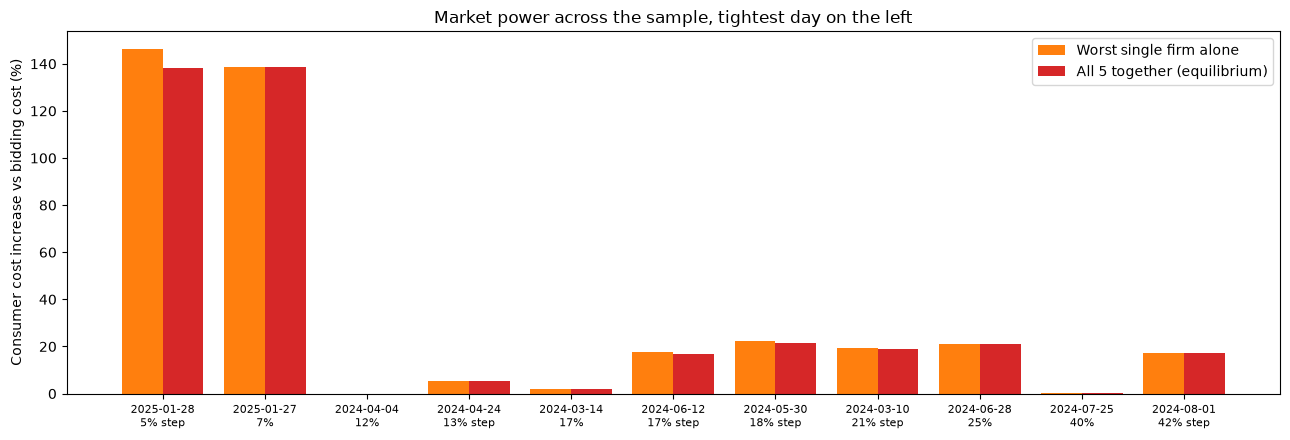

In [7]:
c = compare.reset_index()
labels = [f"{d.date()}\n{s:.0f}%{' step' if n else ''}" for d, s, n in zip(c["Date"], c["Spare %"], c["Near step"])]
x = np.arange(len(c))

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(x - 0.2, c["Consumer +%, worst single firm"], 0.4, color="tab:orange", label="Worst single firm alone")
ax.bar(x + 0.2, c["Consumer +%, all 5 together"], 0.4, color="tab:red", label="All 5 together (equilibrium)")
ax.set_xticks(x, labels, fontsize=8)
ax.set_ylabel("Consumer cost increase vs bidding cost (%)")
ax.set_title("Market power across the sample, tightest day on the left")
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
prof = eq_firms.groupby("Firm")[["Profit_cost", "Profit_eq"]].sum().reindex(FIRMS) / 1e7
alone_prof = alone.groupby("Firm")[["Profit_best"]].sum().reindex(FIRMS) / 1e7
summary = pd.DataFrame({"At cost": prof["Profit_cost"], "Alone (best)": alone_prof["Profit_best"],
                        "Together (equilibrium)": prof["Profit_eq"]})
print("Total profit over the 11 sample days (Rs crore per peak hour, summed):")
summary.round(2)

Total profit over the 11 sample days (Rs crore per peak hour, summed):


,At cost,Alone (best),Together (equilibrium)
Firm,,,
NR UP,28.89,44.42,46.13
WR Maharashtra,37.34,56.39,72.34
Chhattisgarh,30.85,34.99,55.13
MP,37.14,41.94,62.26
Gujarat,53.95,69.28,85.12


### Does the order of moves matter?

In every equilibrium only one or two firms mark up and the others keep bidding cost. The loop lets the firms move in a fixed order (UP first). If the first mover becomes the price-setter, a different order could give a different equilibrium. Check: the same days with the order **reversed** (Gujarat first).

In [9]:
rows = []
for d in sample.index:
    rev = equilibrium(model, blocks, demand.loc[d], lookup[d], FIRMS[::-1], max_rounds=5)
    s = market_summary(rev["result"], blocks)
    leaders = lambda adders: ", ".join(f"{f} +{a}" for f, a in adders.items() if a > 0) or "none"
    rows.append({"Date": d.date(), "Spare %": sample.loc[d, "Spare %"],
                 "UP first: who marks up": leaders(eq_firms[eq_firms["Date"] == d].set_index("Firm")["Adder"].to_dict()),
                 "Gujarat first: who marks up": leaders(rev["adders"]), "Status (reversed)": rev["status"],
                 "Price, UP first": together.loc[d, "Price_avg_eq"], "Price, Gujarat first": s["Price_avg"]})
order = pd.DataFrame(rows).sort_values("Spare %")
order["Price difference"] = order["Price, Gujarat first"] - order["Price, UP first"]
order.round(0)

,Date,Spare %,UP first: who marks up,Gujarat first: who marks up,Status (reversed),"Price, UP first","Price, Gujarat first",Price difference
0,2025-01-28,5.0,NR UP +6775,Gujarat +5175,converged,8985.0,8833.0,-152.0
1,2025-01-27,7.0,NR UP +6775,Gujarat +7964,converged,8955.0,8755.0,-200.0
3,2024-04-04,12.0,none,none,converged,3683.0,3683.0,0.0
2,2024-04-24,13.0,NR UP +1525,"Chhattisgarh +1873, WR Maharashtra +1000",converged,3754.0,3726.0,-28.0
4,2024-06-12,17.0,NR UP +1275,Gujarat +2498,converged,3443.0,3462.0,20.0
5,2024-03-14,17.0,WR Maharashtra +698,"MP +1750, WR Maharashtra +698",converged,3456.0,3456.0,0.0
10,2024-05-30,18.0,NR UP +1275,"Gujarat +598, WR Maharashtra +698",converged,3409.0,3422.0,13.0
6,2024-03-10,21.0,NR UP +1075,MP +1750,converged,3377.0,3397.0,21.0
7,2024-06-28,25.0,WR Maharashtra +698,WR Maharashtra +698,converged,3432.0,3432.0,0.0
9,2024-07-25,40.0,Gujarat +498,Gujarat +498,converged,2709.0,2709.0,0.0


## Conclusions

| # | Hypothesis | Result |
|---|---|---|
| 1 | Every big firm marks up on most days, not only tight ones | ✅ Alone, each firm marks up on **45–82%** of the sample days, including slack ones (42% spare: +17% for consumers) |
| 2 | With rivals also strategic, prices end up **higher** than with one firm alone | ❌ **About the same, or slightly lower.** Together, prices are within Rs 0–310 of the worst single firm's |
| 3 | Some days cycle | ❌ **All 11 days converge**, in 1–2 rounds. No ties |

**1. One firm leads, the others free-ride.** In equilibrium, **only one firm marks up on 9 of 11 days** (two firms on one day, none on one). Once a leader raises the price, the other big firms are better off **bidding cost**: they sell their full output at the leader's higher price, without giving up any sales. This is a **price umbrella**: the leader holds the price up and everyone under it profits.

**2. Who leads isn't determined, but the price is.** Reversing the order of moves (Gujarat first instead of UP) changes *who* leads on 8 of 11 days, but prices differ by at most **Rs 200/MWh** (usually under Rs 30). There are several equilibria with nearly the same market price. So **"how much consumers pay" is a robust result; "which firm exercises market power" is not.**

**3. Rivals don't discipline each other here.** With the five largest firms all strategic, consumers pay about as much as when the worst single firm acts alone: **+138% on the two tightest days, +17% to +22% on five of the moderate and slack days**, and roughly 0–5% on the others. Competition between big firms doesn't bring prices back down, because undercutting the leader means selling a bit more at a lower price, which is less attractive than free-riding at the high one.

**4. Everyone profits more together.** Each firm's total profit over the sample is higher in equilibrium than when it acts alone (Chhattisgarh 35 → 55, MP 42 → 62 crore): the free-riders gain without raising their own bids.

**5. Market power depends on the step structure, not only tightness.** No firm marks up at all on 4 Apr 2024 (12% spare): the price is already set by a block above the big firms' costs, so there is no step for them to move. Two days with the same spare capacity (17%) differ: +2% vs +17% for consumers.

**Caveats:** one firm per state (each "firm" owns all of its state's strategic capacity, an upper bound); 5 strategic firms only, the other 19 large firms bid cost; bid only, no withholding; a sample of 11 days, not a full year. The full 396-day, 24-firm runs are deferred (`docs/part3_plan.md`).

## Save

In [10]:
out = pd.concat([
    alone.assign(Experiment="alone").rename(columns={"Profit_best": "Profit", "Price_avg_best": "Price_avg",
                                                       "Consumer_cost_best": "Consumer_cost", "Unserved_MW_best": "Unserved_MW"}),
    eq_firms.merge(together.reset_index()[["Date", "Status", "Rounds", "Price_avg_cost", "Price_avg_eq",
                                           "Consumer_cost_cost", "Consumer_cost_eq", "Unserved_MW_eq"]], on="Date")
            .assign(Experiment="together")
            .rename(columns={"Profit_eq": "Profit", "Price_avg_eq": "Price_avg", "Consumer_cost_eq": "Consumer_cost",
                             "Unserved_MW_eq": "Unserved_MW"}),
], ignore_index=True)
out = out.merge(sample[["Band", "Near_step", "Spare %"]].reset_index(), on="Date")
cols = ["Date", "Band", "Near_step", "Spare %", "Experiment", "Firm", "Adder", "Profit_cost", "Profit",
        "Price_avg_cost", "Price_avg", "Consumer_cost_cost", "Consumer_cost", "Unserved_MW", "Status", "Rounds"]
out[cols].to_csv("../data/processed/strategic_sample_results.csv", index=False)
print(f"strategic_sample_results.csv: {len(out)} rows")

strategic_sample_results.csv: 110 rows
